# Fase 2 - Clustering y perfilamiento socio-tecnológico

Este notebook implementa el análisis no supervisado del proyecto **Brecha Digital y Rendimiento Escolar en el Perú (2025)**. Se emplean imputación por mediana, `RobustScaler`, evaluación de $k=2,\dots,8$, K-Means, Gaussian Mixture, PCA y UMAP.

La variable `rezago_escolar` no participa en el ajuste: se utiliza únicamente como contraste descriptivo externo para evitar circularidad.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import config
from src.clustering import CLUSTER_FEATURES, ejecutar_fase2
print('Proyecto:', ROOT)
print('Semilla:', config.RANDOM_STATE)

Proyecto: C:\Users\Jalea\Documents\U\C8\inteligencia_artificial\u2_ex\proyecto_ia
Semilla: 42


## 1. Carga del dataset maestro

In [2]:
df = pd.read_parquet(config.DATASET_FINAL_PARQUET)
print(f'Dataset: {df.shape[0]:,} filas x {df.shape[1]} columnas')
print('Variables de clustering:', len(CLUSTER_FEATURES))
CLUSTER_FEATURES

Dataset: 23,668 filas x 50 columnas
Variables de clustering: 10


['log_gasto_pc',
 'log_ingreso_pc',
 'internet_hogar',
 'luz_electrica',
 'equipamiento_tic',
 'uso_internet_mes',
 'estrato_rural',
 'escale_ratio_alumno_docente',
 'escale_pct_colegios_publicos',
 'escale_pct_locales_rurales']

## 2. Ejecución reproducible

Las métricas de selección de $k$ se calculan sobre una muestra reproducible de 3,000 observaciones, debido al costo cuadrático de Silhouette. Los modelos finales asignan un cluster a las 106,958 observaciones. UMAP se calcula sobre 1,000 casos para visualización.

In [3]:
# Para regenerar completamente los artefactos, descomente la línea siguiente:
# resultados = ejecutar_fase2(df, random_state=config.RANDOM_STATE)
resultados = {
    'metrics': pd.read_csv(config.REPORTS_DIR / 'clustering_metricas_k.csv'),
    'comparison': pd.read_csv(config.REPORTS_DIR / 'clustering_comparacion_modelos.csv'),
    'profiles': pd.read_csv(config.REPORTS_DIR / 'perfiles_clusters.csv'),
}
print('Artefactos validados de la Fase 2 cargados correctamente.')

Artefactos validados de la Fase 2 cargados correctamente.


## 3. Selección del número de clusters

In [4]:
metricas = resultados['metrics']
metricas.style.format({'inercia':'{:.2f}', 'silhouette':'{:.4f}', 'davies_bouldin':'{:.4f}', 'calinski_harabasz':'{:.2f}'})

,k,inercia,silhouette,davies_bouldin,calinski_harabasz,score_balance
0,2,5320.49,0.3233,1.2251,1769.02,3.000000
1,3,4436.17,0.2364,1.4203,1359.19,2.571429
2,4,3887.68,0.2177,1.4583,1174.52,2.142857
3,5,3599.79,0.1835,1.5363,1010.90,1.285714
4,6,3336.34,0.1819,1.4876,919.58,1.428571
5,7,3145.99,0.1783,1.5046,842.59,1.000000
6,8,2994.21,0.1638,1.5085,780.24,0.571429


## 4. Comparación K-Means vs Gaussian Mixture

In [5]:
resultados['comparison'].style.format({'silhouette':'{:.4f}', 'davies_bouldin':'{:.4f}', 'calinski_harabasz':'{:.2f}'})

,modelo,silhouette,davies_bouldin,calinski_harabasz
0,KMeans,0.3233,1.2251,1769.02
1,GaussianMixture,0.1538,2.2979,205.76


## 5. Perfiles socioeducativos y contraste externo con rezago

In [6]:
perfiles = resultados['profiles']
perfiles[['cluster_kmeans','nombre_cluster','n','internet_hogar','uso_internet_mes','estrato_rural','tasa_rezago','tasa_exclusion_digital']]

,cluster_kmeans,nombre_cluster,n,internet_hogar,uso_internet_mes,estrato_rural,tasa_rezago,tasa_exclusion_digital
0,0,Rural vulnerable con aislamiento digital y dep...,10239,0.914933,0.586971,6.388417,0.061858,0.031351
1,1,Urbano consolidado con alta conectividad y mej...,13429,0.980118,0.831559,2.834463,0.050659,0.000819


## 6. Visualizaciones PCA, UMAP y métricas

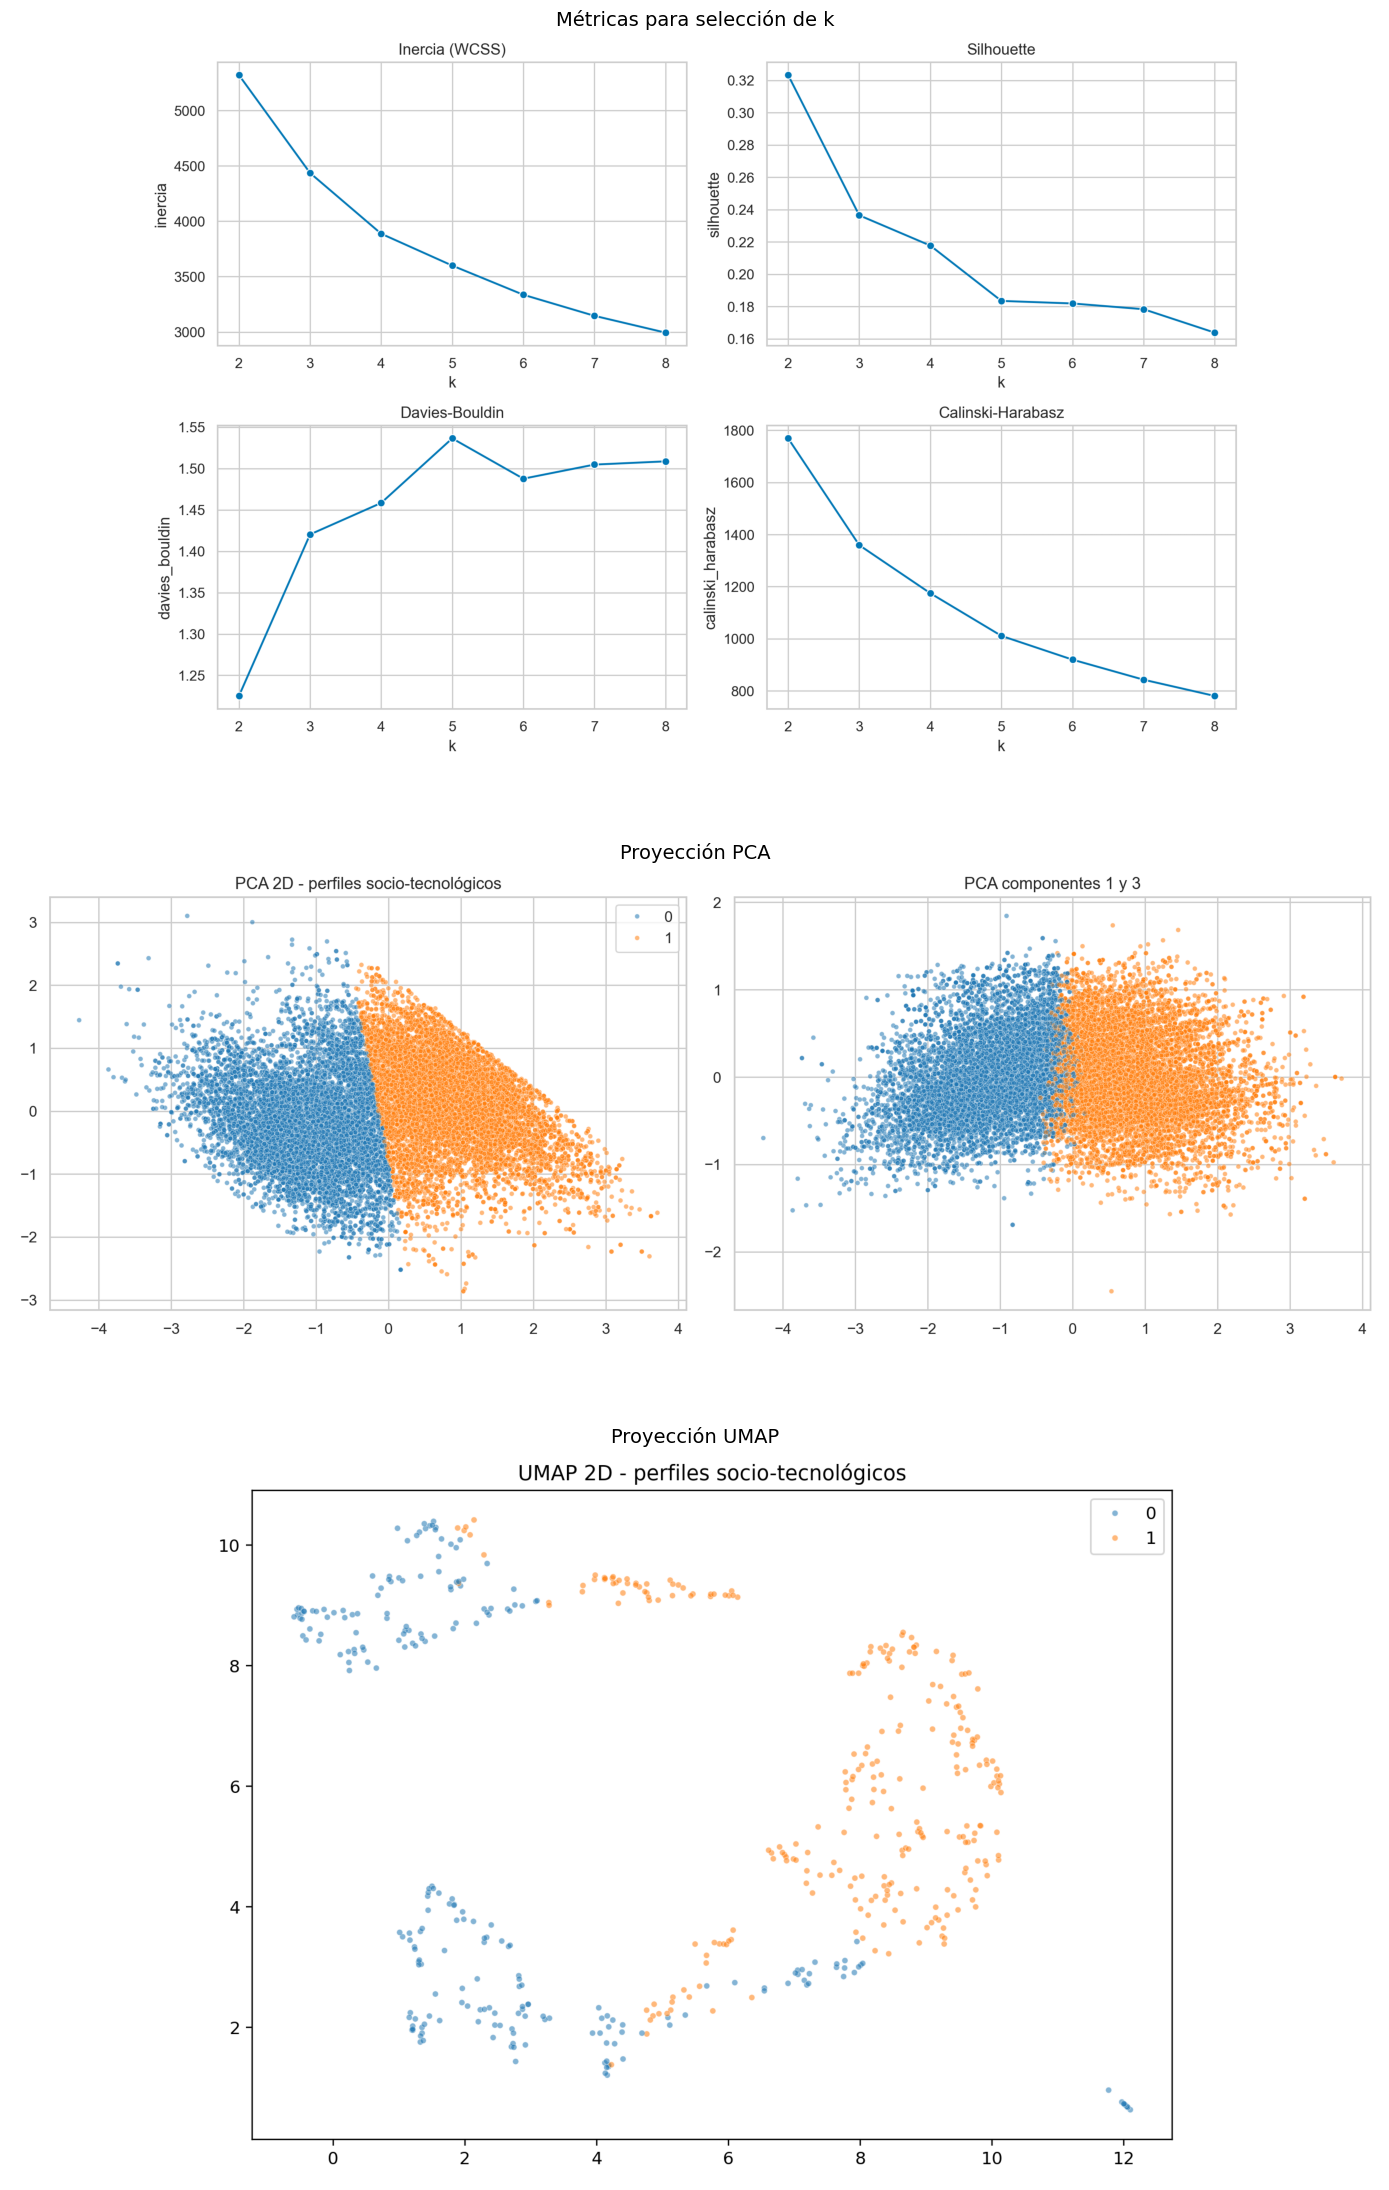

In [7]:
fig, axes = plt.subplots(3, 1, figsize=(14, 22))
for ax, name, title in zip(axes, ['clustering_metricas_k.png','pca_clusters.png','umap_clusters.png'], ['Métricas para selección de k','Proyección PCA','Proyección UMAP']):
    ax.imshow(plt.imread(config.FIGURES_DIR / name))
    ax.set_title(title, fontsize=14)
    ax.axis('off')
plt.tight_layout()

## Conclusión de la Fase 2

El balance conjunto de Silhouette, Davies-Bouldin y Calinski-Harabasz selecciona **$k=2$**. Los perfiles distinguen un grupo rural vulnerable, con menor conectividad y mayor dependencia pública, y un grupo urbano consolidado, con mayor conectividad y recursos. La tasa de rezago se utiliza después del ajuste y confirma diferencias entre perfiles sin contaminar la formación de clusters.